# 01 — GTFS Ingestion

Downloads (if needed) and validates the Community Transit GTFS feed, then
computes per-stop trip frequencies for a representative weekday.

**Output:** `data/processed/stop_frequencies.parquet`

In [1]:
import zipfile
import urllib.request
from pathlib import Path

import sys
sys.path.insert(0, str(Path('..').resolve()))

from transit_gaps.gtfs import load_feed, compute_stop_frequencies

In [2]:
GTFS_URL = "https://www.communitytransit.org/docs/default-source/open-data/gtfs/current.zip?sfvrsn=988306d7_104"
GTFS_DIR = Path("../data/raw/gtfs")
GTFS_ZIP = GTFS_DIR / "google_transit.zip"

GTFS_DIR.mkdir(parents=True, exist_ok=True)

if not any(GTFS_DIR.glob("*.txt")):
    print(f"Downloading GTFS feed from Community Transit...")
    urllib.request.urlretrieve(GTFS_URL, GTFS_ZIP)
    with zipfile.ZipFile(GTFS_ZIP, 'r') as z:
        z.extractall(GTFS_DIR)
    print("Extracted.")
else:
    print("GTFS files already present — skipping download.")

list(GTFS_DIR.glob("*.txt"))

GTFS files already present — skipping download.


[PosixPath('../data/raw/gtfs/direction_names_exceptions.txt'),
 PosixPath('../data/raw/gtfs/shapes.txt'),
 PosixPath('../data/raw/gtfs/calendar.txt'),
 PosixPath('../data/raw/gtfs/stops.txt'),
 PosixPath('../data/raw/gtfs/stop_times.txt'),
 PosixPath('../data/raw/gtfs/stop_order_exceptions.txt'),
 PosixPath('../data/raw/gtfs/agency.txt'),
 PosixPath('../data/raw/gtfs/routes.txt'),
 PosixPath('../data/raw/gtfs/transfers.txt'),
 PosixPath('../data/raw/gtfs/calendar_dates.txt'),
 PosixPath('../data/raw/gtfs/feed_info.txt'),
 PosixPath('../data/raw/gtfs/trips.txt')]

In [3]:
feed = load_feed(GTFS_DIR)

# Feed info — check validity dates
print(feed.feed_info)
print(f"Stops: {len(feed.stops)}")
print(f"Routes: {len(feed.routes)}")
print(f"Trips: {len(feed.trips)}")

  feed_publisher_name                feed_publisher_url feed_lang  \
0   Community Transit  http://www.communitytransit.org/        en   

       feed_contact_email feed_start_date feed_end_date       feed_version  
0  OpenData@commtrans.org        20260318      20260612  20260318-20260828  
Stops: 1758
Routes: 40
Trips: 9993


In [12]:
# GTFS validation summary
import gtfs_kit as gk
# Summary description of the feed                                 
print(feed.describe())
# Quality assessment (replaces validate)                          
quality = feed.assess_quality()
print(quality)                                                    
# print(quality[quality['type'] == 'error'])
# print(quality[quality['type'] == 'warning'].head(10))

                           indicator                               value
0                           agencies  [Community Transit, Sound Transit]
1                           timezone                 America/Los_Angeles
2                         start_date                            20260318
3                           end_date                            20260828
4                         num_routes                                  40
5                          num_trips                                9993
6                          num_stops                                1758
7                         num_shapes                                 106
8                        sample_date                            20260326
9   num_routes_active_on_sample_date                                  40
10   num_trips_active_on_sample_date                                2260
11   num_stops_active_on_sample_date                                1697
                             indicator      value
0

In [13]:
stop_freq = compute_stop_frequencies(feed=feed, out_path="../data/processed/stop_frequencies.parquet")
stop_freq.head()

Representative service_id: MCOB-DO:121:0:Weekday:2:26MAR:12345
Saved stop frequencies → ../data/processed/stop_frequencies.parquet  (1680 stops)


,stop_id,trips_per_day,trips_peak,trips_offpeak,geometry
0,1,17,8,9,POINT (-122.1955 48.05579)
1,7,17,8,9,POINT (-122.20092 48.05479)
2,12,19,8,11,POINT (-122.27667 48.06086)
3,13,19,8,11,POINT (-122.2747 48.05928)
4,18,19,9,10,POINT (-122.20524 48.0532)


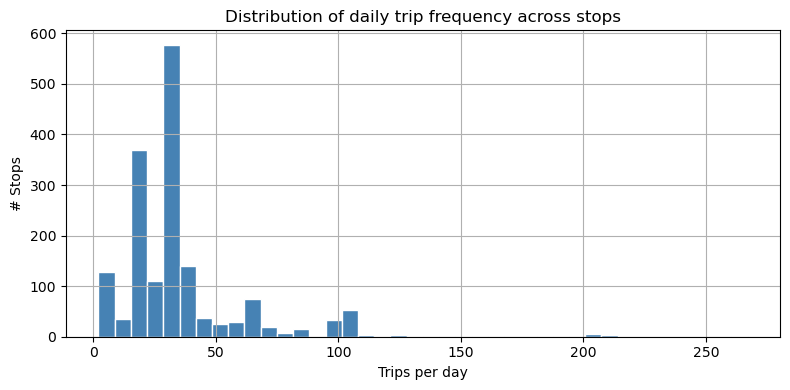

count    1680.000000
mean       35.942857
std        28.550390
min         2.000000
25%        18.000000
50%        32.000000
75%        37.000000
max       267.000000
Name: trips_per_day, dtype: float64


In [14]:
# QA: distribution of trips per stop
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
stop_freq['trips_per_day'].hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Trips per day')
ax.set_ylabel('# Stops')
ax.set_title('Distribution of daily trip frequency across stops')
plt.tight_layout()
plt.show()

print(stop_freq['trips_per_day'].describe())

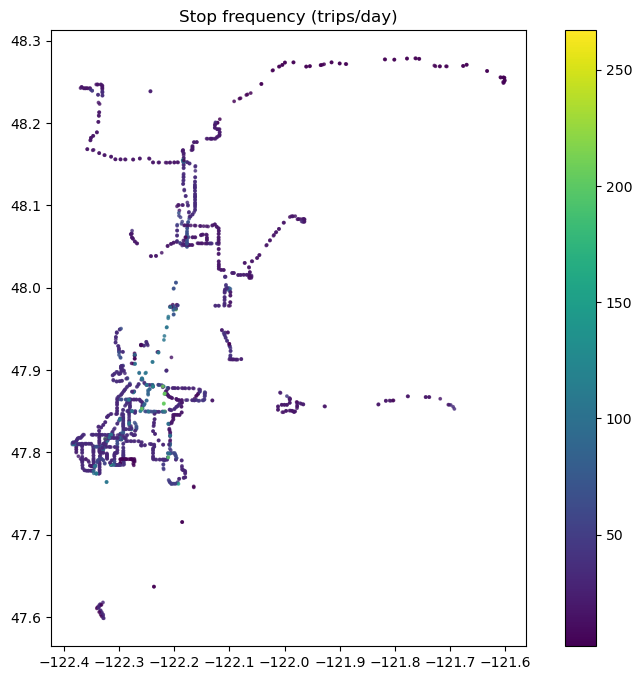

In [15]:
# QA: quick map of stop locations
ax = stop_freq.plot(
    column='trips_per_day', cmap='viridis', markersize=3,
    legend=True, figsize=(10, 8), alpha=0.7
)
ax.set_title('Stop frequency (trips/day)')
plt.show()